<a href="https://colab.research.google.com/github/Hasini-uni/DAVlab/blob/main/lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np


df = pd.read_csv('StudentPerformanceFactors[1].csv')

print("Original Dataset:")
print(df)
print("\nStatistical Summary:")
print(df.describe())


Original Dataset:
      Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0                23          84                  Low                High   
1                19          64                  Low              Medium   
2                24          98               Medium              Medium   
3                29          89                  Low              Medium   
4                19          92               Medium              Medium   
...             ...         ...                  ...                 ...   
6602             25          69                 High              Medium   
6603             23          76                 High              Medium   
6604             20          90               Medium                 Low   
6605             10          86                 High                High   
6606             15          67               Medium                 Low   

     Extracurricular_Activities  Sleep_Hours  Previous_Scores  \
0   

In [2]:
df = df.select_dtypes(include=np.number)

# Remove rows containing missing numerical values
df = df.dropna()

# Display
print("Numerical Dataset:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)


Numerical Dataset:
   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0             23          84            7               73                  0   
1             19          64            8               59                  2   
2             24          98            7               91                  2   
3             29          89            8               98                  1   
4             19          92            6               65                  3   

   Physical_Activity  Exam_Score  
0                  3          67  
1                  4          61  
2                  4          74  
3                  4          71  
4                  4          70  

Dataset Shape:
(6607, 7)


In [3]:
# Import MinMaxScaler
from sklearn.preprocessing import MinMaxScaler

# Initialize MinMaxScaler
scaler = MinMaxScaler()

# Apply normalization
normalized_data = scaler.fit_transform(df)

# Convert normalized data into a DataFrame
normalized_df = pd.DataFrame(
    normalized_data,
    columns=df.columns
)

# Display
print("Normalized Dataset:")
print(normalized_df.head().round(2))

# Verify
print("\nMinimum Values:")
print(normalized_df.min())
print("\nMaximum Values:")
print(normalized_df.max())


Normalized Dataset:
   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0           0.51        0.60         0.50             0.46               0.00   
1           0.42        0.10         0.67             0.18               0.25   
2           0.53        0.95         0.50             0.82               0.25   
3           0.65        0.73         0.67             0.96               0.12   
4           0.42        0.80         0.33             0.30               0.38   

   Physical_Activity  Exam_Score  
0               0.50        0.26  
1               0.67        0.13  
2               0.67        0.41  
3               0.67        0.35  
4               0.67        0.33  

Minimum Values:
Hours_Studied        0.0
Attendance           0.0
Sleep_Hours          0.0
Previous_Scores      0.0
Tutoring_Sessions    0.0
Physical_Activity    0.0
Exam_Score           0.0
dtype: float64

Maximum Values:
Hours_Studied        1.0
Attendance           1.0
Sleep_Hou

In [4]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Apply standardization
standardized_data = scaler.fit_transform(df)

# Convert standardized data into a DataFrame
standardized_df = pd.DataFrame(
    standardized_data,
    columns=df.columns
)

# Display the standardized dataset
print("Standardized Dataset:")
print(standardized_df.head().round(2))

print("\nMean of Each Feature:")
print(standardized_df.mean().round(2))

print("\nStandard Deviation of Each Feature:")
print(standardized_df.std(ddof=0).round(2))


Standardized Dataset:
   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0           0.50        0.35        -0.02            -0.14              -1.21   
1          -0.16       -1.38         0.66            -1.12               0.41   
2           0.67        1.56        -0.02             1.11               0.41   
3           1.51        0.78         0.66             1.59              -0.40   
4          -0.16        1.04        -0.70            -0.70               1.22   

   Physical_Activity  Exam_Score  
0               0.03       -0.06  
1               1.00       -1.60  
2               1.00        1.74  
3               1.00        0.97  
4               1.00        0.71  

Mean of Each Feature:
Hours_Studied       -0.0
Attendance          -0.0
Sleep_Hours         -0.0
Previous_Scores      0.0
Tutoring_Sessions    0.0
Physical_Activity   -0.0
Exam_Score          -0.0
dtype: float64

Standard Deviation of Each Feature:
Hours_Studied        1.0
Attend

In [5]:

# Import required libraries
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Standardize the dataset
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

# Apply PCA to reduce the features to two components
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

# Create a DataFrame for PCA output
pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)

# Display
print("PCA Transformed Data:")
print(pca_df.head().round(2))

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Retained:")
print(pca.explained_variance_ratio_.sum())


PCA Transformed Data:
    PC1   PC2
0  0.15  0.59
1 -2.06 -0.19
2  2.59  0.04
3  1.91  1.56
4  1.09 -1.61

Explained Variance Ratio:
[0.25214912 0.1499744 ]

Total Variance Retained:
0.4021235201240285


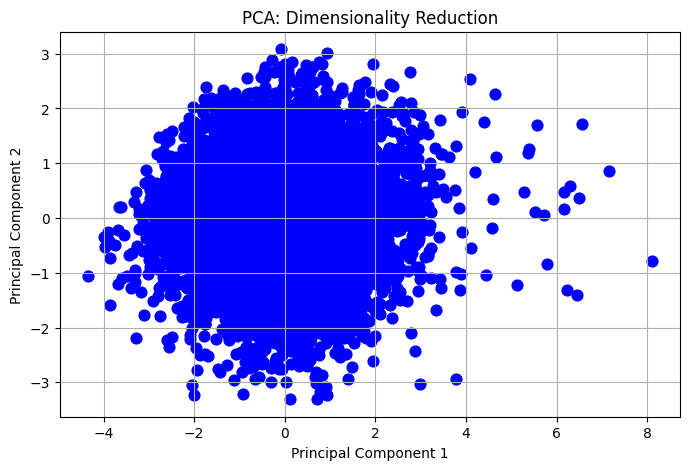

In [6]:
# Create a scatter plot of the two principal components
plt.figure(figsize=(8, 5))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    color='blue',
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Dimensionality Reduction")

# Display grid and plot
plt.grid(True)
plt.show()


In [7]:
# Compare the original, normalized and standardized datasets
print("Original Dataset:")
print(df.head())

print("\nNormalized Dataset:")
print(normalized_df.head().round(2))

print("\nStandardized Dataset:")
print(standardized_df.head().round(2))

print("\nPCA Transformed Dataset:")
print(pca_df.head().round(2))


Original Dataset:
   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0             23          84            7               73                  0   
1             19          64            8               59                  2   
2             24          98            7               91                  2   
3             29          89            8               98                  1   
4             19          92            6               65                  3   

   Physical_Activity  Exam_Score  
0                  3          67  
1                  4          61  
2                  4          74  
3                  4          71  
4                  4          70  

Normalized Dataset:
   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0           0.51        0.60         0.50             0.46               0.00   
1           0.42        0.10         0.67             0.18               0.25   
2           0.53     